# Implementation of AI in Concrete Mixing – Aggregate Shape Classification

**Project goal:** Use machine learning to classify coarse aggregate shape as **A = Elongated, B = Angular, C = Cubical, D = Rounded** from the measurements and shape descriptors in the supplied Excel dataset.

> The supplied dataset contains only 24 table/sieve-fraction summary rows (6 rows per class), so this notebook uses **stratified 5-fold cross-validation** instead of relying on a single 80/20 split. The small sample size means model accuracy should be treated as exploratory, not as a production-ready accuracy estimate.

## Step 1 – Install/import libraries

In [2]:
# Google Colab normally has these packages already.
# Run this cell if any package is missing.

!pip -q install openpyxl scikit-learn joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)

import joblib

## Step 2 – Upload the Excel dataset
Upload **Aggregate_AI_Colab_READY.xlsx** when Colab asks for a file.

In [3]:
uploaded = files.upload()

file_name = "Aggregate_AI_Colab_READY.xlsx"
if file_name not in uploaded:
    # Use the first uploaded Excel file if the exact name was changed.
    excel_files = [name for name in uploaded if name.lower().endswith((".xlsx", ".xls"))]
    if not excel_files:
        raise FileNotFoundError("Please upload the Excel dataset.")
    file_name = excel_files[0]

print("Using:", file_name)

Saving Aggregate_AI_Colab_READY.xlsx to Aggregate_AI_Colab_READY.xlsx
Using: Aggregate_AI_Colab_READY.xlsx


## Step 3 – Read the ML-ready sheet
The workbook contains a sheet named **ML_Ready_Data** prepared for classification.

In [4]:
df = pd.read_excel(file_name, sheet_name="ML_Ready_Data")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Rows: 24
Columns: 14


,Sieve_Size_Midpoint_mm,Longest_dl_mm,Intermediate_di_mm,Shortest_ds_mm,Volume_Archimedes_mm3,Volume_Equivalent_Shape_1_mm3,Volume_Equivalent_Shape_2_mm3,Equivalent_Sphere_Diameter_Dp_mm,Sphericity,Shape_Factor,Elongation_Ratio,Flatness_Ratio,Aggregate_Type,Aggregate_Type_Code
0,5.525,16.10,5.40,4.30,300,293.61,186.92,8.25,0.45,0.46,2.98,3.74,Elongated,A
1,8.150,16.69,10.75,6.31,850,889.39,566.20,11.93,0.62,0.47,1.55,2.64,Elongated,A
2,11.250,20.57,10.75,8.71,1500,1513.54,963.55,14.25,0.60,0.59,1.91,2.36,Elongated,A
3,14.250,27.40,12.75,10.88,3000,2983.87,1899.59,17.86,0.57,0.58,2.15,2.52,Elongated,A
4,18.000,43.70,23.00,12.50,8000,9867.55,6281.88,26.61,0.53,0.39,1.90,3.50,Elongated,A


## Step 4 – Understand the target classes
The target is **Aggregate_Type**. The workbook also provides **Aggregate_Type_Code**:

- A = Elongated
- B = Angular
- C = Cubical
- D = Rounded

The code column is the **target encoding only**. It must NOT be used as an input feature.

In [5]:
print(df["Aggregate_Type"].value_counts())

class_map = {
    "A": "Elongated",
    "B": "Angular",
    "C": "Cubical",
    "D": "Rounded"
}

print("\nClass mapping:")
for code, name in class_map.items():
    print(code, "=", name)

Aggregate_Type
Elongated    6
Angular      6
Cubical      6
Rounded      6
Name: count, dtype: int64

Class mapping:
A = Elongated
B = Angular
C = Cubical
D = Rounded


## Step 5 – Check data quality

In [6]:
print("Missing values:")
display(df.isna().sum().to_frame("Missing"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

Missing values:


,Missing
Sieve_Size_Midpoint_mm,0
Longest_dl_mm,0
Intermediate_di_mm,0
Shortest_ds_mm,0
Volume_Archimedes_mm3,0
Volume_Equivalent_Shape_1_mm3,0
Volume_Equivalent_Shape_2_mm3,0
Equivalent_Sphere_Diameter_Dp_mm,0
Sphericity,0
Shape_Factor,0



Duplicate rows: 0

Data types:


,dtype
Sieve_Size_Midpoint_mm,float64
Longest_dl_mm,float64
Intermediate_di_mm,float64
Shortest_ds_mm,float64
Volume_Archimedes_mm3,int64
Volume_Equivalent_Shape_1_mm3,float64
Volume_Equivalent_Shape_2_mm3,float64
Equivalent_Sphere_Diameter_Dp_mm,float64
Sphericity,float64
Shape_Factor,float64


## Step 6 – Define the target and features
We remove both target columns:

- `Aggregate_Type` → target
- `Aggregate_Type_Code` → encoded target, NOT a feature

All remaining numeric columns are candidate input features.

In [7]:
target_col = "Aggregate_Type_Code"

feature_cols = [
    c for c in df.columns
    if c not in ["Aggregate_Type", "Aggregate_Type_Code"]
]

X = df[feature_cols].copy()
y = df[target_col].copy()

print("Number of features:", X.shape[1])
print("Features:")
for c in feature_cols:
    print(" -", c)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Number of features: 12
Features:
 - Sieve_Size_Midpoint_mm
 - Longest_dl_mm
 - Intermediate_di_mm
 - Shortest_ds_mm
 - Volume_Archimedes_mm3
 - Volume_Equivalent_Shape_1_mm3
 - Volume_Equivalent_Shape_2_mm3
 - Equivalent_Sphere_Diameter_Dp_mm
 - Sphericity
 - Shape_Factor
 - Elongation_Ratio
 - Flatness_Ratio

X shape: (24, 12)
y shape: (24,)


## Step 7 – Basic exploratory data analysis

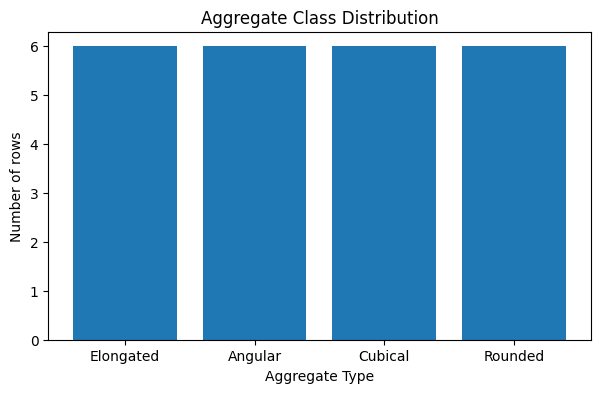

,count,mean,std,min,25%,50%,75%,max
Sieve_Size_Midpoint_mm,24.0,13.279167,5.880040,5.525,8.1500,12.750,18.0000,22.50
Longest_dl_mm,24.0,19.773333,8.941055,7.820,13.1250,18.545,26.5750,43.70
Intermediate_di_mm,24.0,12.825000,5.816999,5.250,8.5575,12.215,16.7950,23.30
Shortest_ds_mm,24.0,10.366250,4.318856,4.300,6.1550,10.180,14.0250,18.85
Volume_Archimedes_mm3,24.0,2587.083333,2740.202276,100.000,412.5000,1475.000,3875.0000,8500.00
Volume_Equivalent_Shape_1_mm3,24.0,3992.555417,3966.976123,256.620,775.9150,2447.415,6109.9525,13229.38
Volume_Equivalent_Shape_2_mm3,24.0,2276.741167,2299.624890,131.640,474.7470,1241.795,3807.0725,7690.13
Equivalent_Sphere_Diameter_Dp_mm,24.0,16.400833,6.839493,6.310,10.8150,15.095,21.8550,29.34
Sphericity,24.0,0.707083,0.112500,0.450,0.6575,0.695,0.7625,0.89
Shape_Factor,24.0,0.669167,0.110135,0.390,0.6125,0.710,0.7425,0.79


In [8]:
# Class distribution
counts = df["Aggregate_Type"].value_counts().reindex(
    ["Elongated", "Angular", "Cubical", "Rounded"]
)

plt.figure(figsize=(7,4))
plt.bar(counts.index, counts.values)
plt.xlabel("Aggregate Type")
plt.ylabel("Number of rows")
plt.title("Aggregate Class Distribution")
plt.xticks(rotation=0)
plt.show()

# Summary statistics
display(X.describe().T)

## Step 8 – Look at important shape measurements
The thesis describes aggregate morphology using longest, intermediate and shortest dimensions and shape descriptors such as sphericity, shape factor, elongation ratio and flatness ratio.

In [9]:
shape_cols = [
    "Longest_dl_mm",
    "Intermediate_di_mm",
    "Shortest_ds_mm",
    "Sphericity",
    "Shape_Factor",
    "Elongation_Ratio",
    "Flatness_Ratio"
]

display(df[["Aggregate_Type"] + shape_cols].head(12))

# Mean shape descriptors by class
group_means = df.groupby("Aggregate_Type")[shape_cols].mean()
display(group_means)

,Aggregate_Type,Longest_dl_mm,Intermediate_di_mm,Shortest_ds_mm,Sphericity,Shape_Factor,Elongation_Ratio,Flatness_Ratio
0,Elongated,16.10,5.40,4.30,0.45,0.46,2.98,3.74
1,Elongated,16.69,10.75,6.31,0.62,0.47,1.55,2.64
2,Elongated,20.57,10.75,8.71,0.60,0.59,1.91,2.36
3,Elongated,27.40,12.75,10.88,0.57,0.58,2.15,2.52
4,Elongated,43.70,23.00,12.50,0.53,0.39,1.90,3.50
5,Elongated,30.10,23.30,14.00,0.71,0.53,1.29,2.15
6,Angular,9.20,5.43,5.28,0.70,0.75,1.70,1.74
7,Angular,12.15,6.08,5.90,0.62,0.69,2.00,2.06
8,Angular,16.65,9.68,9.48,0.69,0.75,1.72,1.76
9,Angular,20.40,11.83,11.50,0.69,0.74,1.73,1.77


,Longest_dl_mm,Intermediate_di_mm,Shortest_ds_mm,Sphericity,Shape_Factor,Elongation_Ratio,Flatness_Ratio
Aggregate_Type,,,,,,,
Angular,19.575000,11.495000,11.118333,0.685000,0.738333,1.741667,1.793333
Cubical,19.100000,11.416667,11.135000,0.703333,0.753333,1.685000,1.725000
Elongated,25.760000,14.325000,9.450000,0.580000,0.503333,1.963333,2.818333
Rounded,14.658333,14.063333,9.761667,0.860000,0.681667,0.968333,1.448333


## Step 9 – Optional feature-set comparison
This is important because several volume/shape variables are derived from the same aggregate measurements. Comparing feature sets helps avoid claiming that these are independent measurements.

In [10]:
feature_sets = {
    "All features": feature_cols,
    "Dimensions only": [
        "Sieve_Size_Midpoint_mm",
        "Longest_dl_mm",
        "Intermediate_di_mm",
        "Shortest_ds_mm"
    ],
    "Shape descriptors only": [
        "Sphericity",
        "Shape_Factor",
        "Elongation_Ratio",
        "Flatness_Ratio"
    ]
}

for name, cols in feature_sets.items():
    print(f"{name}: {len(cols)} features")
    print(cols)
    print()

All features: 12 features
['Sieve_Size_Midpoint_mm', 'Longest_dl_mm', 'Intermediate_di_mm', 'Shortest_ds_mm', 'Volume_Archimedes_mm3', 'Volume_Equivalent_Shape_1_mm3', 'Volume_Equivalent_Shape_2_mm3', 'Equivalent_Sphere_Diameter_Dp_mm', 'Sphericity', 'Shape_Factor', 'Elongation_Ratio', 'Flatness_Ratio']

Dimensions only: 4 features
['Sieve_Size_Midpoint_mm', 'Longest_dl_mm', 'Intermediate_di_mm', 'Shortest_ds_mm']

Shape descriptors only: 4 features
['Sphericity', 'Shape_Factor', 'Elongation_Ratio', 'Flatness_Ratio']



## Step 10 – Prepare stratified cross-validation
Because there are only 24 rows, use stratified cross-validation. Each fold preserves the four aggregate classes as much as possible.

Scaling is placed **inside the model pipeline**, so the scaler is fitted only on the training part of each fold.

In [11]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Using 5-fold Stratified Cross-Validation")

Using 5-fold Stratified Cross-Validation


## Step 11 – Build the five ML models
These correspond to the algorithms shown in the project diagram:

1. Logistic Regression
2. KNN
3. Decision Tree
4. Random Forest
5. SVM

In [12]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=3))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=4
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1.0))
    ])
}

print("Models ready:", list(models.keys()))

Models ready: ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'SVM']


## Step 12 – Train and compare models
Use cross-validation accuracy rather than a single train/test accuracy.

In [13]:
results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "Model": name,
        "Mean Accuracy": scores.mean(),
        "Std Accuracy": scores.std(),
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4]
    })

results_df = pd.DataFrame(results).sort_values(
    "Mean Accuracy", ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Mean Accuracy,Std Accuracy,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
0,Logistic Regression,0.88,0.160000,1.0,1.0,0.8,0.6,1.00
1,Decision Tree,0.63,0.140000,0.8,0.6,0.4,0.6,0.75
2,Random Forest,0.59,0.111355,0.6,0.6,0.4,0.6,0.75
3,SVM,0.59,0.210713,0.8,0.6,0.2,0.6,0.75
4,KNN,0.52,0.271293,0.6,0.4,0.2,0.4,1.00


## Step 13 – Plot model comparison

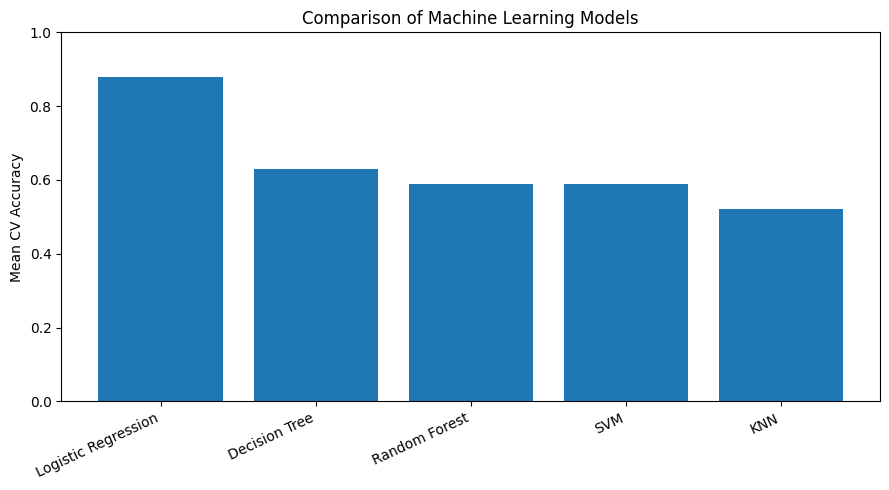

In [14]:
plt.figure(figsize=(9,5))
plt.bar(results_df["Model"], results_df["Mean Accuracy"])
plt.ylim(0, 1)
plt.ylabel("Mean CV Accuracy")
plt.title("Comparison of Machine Learning Models")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## Step 14 – Select the best model
The best model is the model with the highest **mean cross-validation accuracy** in this run.

In [15]:
best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]

print("Best model:", best_model_name)
print("Mean CV accuracy:", round(results_df.loc[0, "Mean Accuracy"], 4))

Best model: Logistic Regression
Mean CV accuracy: 0.88


## Step 15 – Confusion matrix for the selected model
`cross_val_predict` gives an out-of-fold prediction for every row, so the confusion matrix is not based on predictions made on the same data used to fit each fold.

              precision    recall  f1-score   support

 A-Elongated       1.00      1.00      1.00         6
   B-Angular       0.80      0.67      0.73         6
   C-Cubical       0.71      0.83      0.77         6
   D-Rounded       1.00      1.00      1.00         6

    accuracy                           0.88        24
   macro avg       0.88      0.88      0.87        24
weighted avg       0.88      0.88      0.87        24



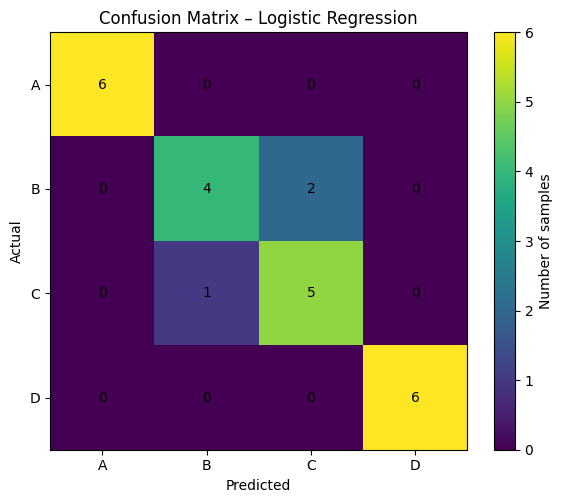

In [16]:
y_pred = cross_val_predict(
    best_model,
    X,
    y,
    cv=cv
)

labels = ["A", "B", "C", "D"]
label_names = ["A-Elongated", "B-Angular", "C-Cubical", "D-Rounded"]

cm = confusion_matrix(y, y_pred, labels=labels)

print(classification_report(
    y,
    y_pred,
    labels=labels,
    target_names=label_names,
    zero_division=0
))

plt.figure(figsize=(6,5))
plt.imshow(cm)
plt.title(f"Confusion Matrix – {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(range(4), labels)
plt.yticks(range(4), labels)

for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar(label="Number of samples")
plt.tight_layout()
plt.show()

## Step 16 – Calculate Accuracy, Precision, Recall and F1-score

In [17]:
accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred, average="macro", zero_division=0)
recall = recall_score(y, y_pred, average="macro", zero_division=0)
f1 = f1_score(y, y_pred, average="macro", zero_division=0)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"],
    "Score": [accuracy, precision, recall, f1]
})

display(metrics_df)

,Metric,Score
0,Accuracy,0.875000
1,Macro Precision,0.878571
2,Macro Recall,0.875000
3,Macro F1,0.874126


## Step 17 – Train the selected model on all 24 rows
This final fitted model is useful for demonstrating a prediction on a new measurement. It is **not** a replacement for collecting a larger independent dataset.

In [18]:
best_model.fit(X, y)

print("Final model fitted on all available rows.")

Final model fitted on all available rows.


## Step 18 – Predict the aggregate type for a new measurement
Enter the same feature columns used during training. The example below uses the first row only as a demonstration.

**Do not use `Aggregate_Type_Code` as an input.**

In [24]:
# Example new sample: copy one existing row for demonstration only.
new_sample = X.iloc[[0]].copy()

pred_code = best_model.predict(new_sample)[0]
pred_name = class_map[pred_code]

print("Predicted code:", pred_code)
print("Predicted aggregate type:", pred_name)

Predicted code: A
Predicted aggregate type: Elongated


In [ ]:
# ==========================
# STEP 18 - Interactive Prediction
# ==========================

print("Enter measurements of a new aggregate particle:")

longest = float(input("Longest Dimension (mm): "))
intermediate = float(input("Intermediate Dimension (mm): "))
shortest = float(input("Shortest Dimension (mm): "))
volume = float(input("Archimedes Volume (mm³): "))
sphere = float(input("Equivalent Sphere Diameter (mm): "))
sphericity = float(input("Sphericity: "))
shape_factor = float(input("Shape Factor: "))
elongation = float(input("Elongation Ratio: "))
flatness = float(input("Flatness Ratio: "))
sieve = float(input("Sieve Size Midpoint (mm): "))

new_sample = pd.DataFrame([{
    "Sieve_Size_Midpoint_mm": sieve,
    "Longest_dl_mm": longest,
    "Intermediate_di_mm": intermediate,
    "Shortest_ds_mm": shortest,
    "Archimedes_Volume_mm3": volume,
    "Equivalent_Cylinder_Volume_mm3": volume,
    "Equivalent_Prism_Volume_mm3": volume,
    "Equivalent_Sphere_Diameter_mm": sphere,
    "Sphericity": sphericity,
    "Shape_Factor": shape_factor,
    "Elongation_Ratio": elongation,
    "Flatness_Ratio": flatness
}])

pred_code = best_model.predict(new_sample)[0]

print("\n--- Prediction Result ---")
print("Aggregate Type Code :", pred_code)
print("Aggregate Type :", class_map[pred_code])

Enter measurements of a new aggregate particle:


## Step 19 – Save the trained model

In [25]:
model_file = "aggregate_shape_classifier.joblib"
joblib.dump({
    "model": best_model,
    "feature_columns": feature_cols,
    "class_map": class_map
}, model_file)

print("Saved:", model_file)
files.download(model_file)

Saved: aggregate_shape_classifier.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 20 – Optional: compare raw dimensions vs derived shape descriptors
This is a useful thesis-quality check because the dataset notes that the volume/shape descriptors are derived from aggregate measurements.

If the shape-descriptor feature set performs much better, report that result carefully: the model is learning relationships already encoded by the measured/derived shape descriptors.

In [23]:
comparison_rows = []

for set_name, cols in feature_sets.items():
    for model_name, model in models.items():
        scores = cross_val_score(
            model,
            df[cols],
            y,
            cv=cv,
            scoring="accuracy"
        )
        comparison_rows.append({
            "Feature Set": set_name,
            "Model": model_name,
            "Mean Accuracy": scores.mean(),
            "Std": scores.std()
        })

feature_comparison = pd.DataFrame(comparison_rows).sort_values(
    "Mean Accuracy", ascending=False
)

display(feature_comparison)

,Feature Set,Model,Mean Accuracy,Std
0,All features,Logistic Regression,0.88,0.160000
11,Shape descriptors only,KNN,0.76,0.149666
12,Shape descriptors only,Decision Tree,0.75,0.077460
13,Shape descriptors only,Random Forest,0.71,0.091652
10,Shape descriptors only,Logistic Regression,0.63,0.060000
2,All features,Decision Tree,0.63,0.140000
3,All features,Random Forest,0.59,0.111355
4,All features,SVM,0.59,0.210713
14,Shape descriptors only,SVM,0.58,0.040000
1,All features,KNN,0.52,0.271293


## Step 21 – Final project conclusion

**Input:** Aggregate measurements and shape descriptors.

**Machine-learning task:** Four-class classification.

**Output:** A / B / C / D aggregate type.

**Application idea:** Use aggregate classification and measured characteristics as supporting information for aggregate selection, particle packing analysis and concrete mix-proportioning decisions.

The ML model should be presented as a **classification/support layer**, not as a complete concrete mix-design system. A larger dataset with independent particle-level observations and concrete performance/mix data would be needed before making strong claims about concrete strength, workability or optimized mix proportions.

## Step 22 – Viva / presentation questions

1. Why did you use machine learning?
2. What is the target variable?
3. Why is this a multiclass classification problem?
4. Why was `Aggregate_Type_Code` not used as an input feature?
5. Why did you use stratified cross-validation?
6. Why is scaling required for KNN, SVM and Logistic Regression?
7. Why compare five models?
8. What is a confusion matrix?
9. What do precision, recall and F1-score mean?
10. What is the limitation of only 24 rows?
11. Which features describe aggregate shape?
12. How can aggregate shape affect packing and concrete mix proportioning?
13. Why should derived shape/volume variables be reported carefully?
14. How would you improve this project with more data?